# Study 6: GP (fitted ls) vs flat (ls pinned), ZOIB linking

Study 6 counterpart of `study9-gp-vs-flat-zoib.ipynb` (the correlation figures). Uses the VBMC fits in
`results/study6-fit-zoib/` (`run_parameter_estimation.py study6-zoib`). Groups: generic (u=0 for every train
feature), specific (u=1), baseline (no statements).

In [1]:
import os
os.environ.setdefault("JAX_ENABLE_X64", "1")
import sys
sys.path.insert(0, ".")

import json
import numpy as np
import matplotlib.pyplot as plt
import plot_style
plot_style.use_lexend()          # Lexend everywhere (DejaVu Sans fills in σ/β)
import jax.numpy as jnp

import inference as inf
import linking as lk
import studies68 as s68

RESULTS = os.path.join('results', 'study6-fit-zoib')
MODEL_SPECS = {                              # model -> posterior file in RESULTS
    'fitted': 'posterior.npz',
    'flat':   'posterior-null.npz',
}
N_PARAMS = {'fitted': 4, 'flat': 3}  # free (mu_0, sigma, [ls], beta)

def _load_median(fname):
    z = np.load(os.path.join(RESULTS, fname), allow_pickle=True)
    return {'ls':    float(np.median(z['ls_samples'])),
            'mu_0':  float(np.median(z['mu0_samples'])),
            'sigma': float(np.median(z['sigma_samples'])),
            'beta':  float(np.median(z['beta_samples'])),
            'elbo':  float(json.loads(str(z['meta']))['elbo']),
            'file':  fname}

MODELS = {name: _load_median(f) for name, f in MODEL_SPECS.items()}
assert MODELS['flat']['ls'] == inf.LS_FLAT, "flat model should have ls pinned at LS_FLAT"

print(f"embedding space: 2d   (flat ls = {inf.LS_FLAT:g})")
print(f"{'model':<13}{'ls':>8}{'mu_0':>8}{'sigma':>8}{'beta':>8}{'n_params':>10}{'ELBO':>10}")
for name, m in MODELS.items():
    print(f"{name:<13}{m['ls']:>8.3g}{m['mu_0']:>+8.3f}{m['sigma']:>8.3f}{m['beta']:>8.3f}{N_PARAMS[name]:>10}{m['elbo']:>10.1f}")

geom, responses_cond = s68.load_study6_prereg(clip_interior=False)    # RAW ratings for the ZOIB
CONDITIONS = list(geom['x_train_cond'])                                # generic, specific, baseline
J = geom['J']
test_feature_names, test_trait = geom['test_feature_names'], geom['test_trait']
emp_cond = {c: np.array(responses_cond[c]).mean(0) for c in CONDITIONS}
N_cond   = {c: int(responses_cond[c].shape[0]) for c in CONDITIONS}
print('n per group:', N_cond)

MODEL_COLOR = {'fitted': '#2a78d6', 'flat': '#eb6834'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})

embedding space: 2d   (flat ls = 10)
model              ls    mu_0   sigma    beta  n_params      ELBO
fitted          0.766  -0.064   0.607   8.945         4   -1254.8
flat               10  -0.006   0.542   9.891         3   -1268.8
load_study6_prereg: 446 of 471 rows kept after exclusions
n per group: {'generic': 148, 'specific': 146, 'baseline': 152}


## Profile the ZOIB linking at each model's posterior median; model predictions per group

In [2]:
fitres = {}
for name, m in MODELS.items():
    ll, link_theta, cond_data = inf.total_log_lik_zoib(
        geom, responses_cond, m['ls'], m['mu_0'], m['sigma'],
        beta_speaker=m['beta'], return_link=True)
    p = lk.unpack(jnp.asarray(link_theta))
    pz1_prior = inf.prior_pz1_modes(geom, m['ls'], m['mu_0'], m['sigma'], beta_speaker=m['beta'])
    logZ_c, pred_cond, pz1_cond, pred_prior = {}, {}, {}, {}
    for c in CONDITIONS:
        logZ_c[c], y_hat, ok = inf.laplace_log_Z(cond_data[c], m['ls'], m['mu_0'], m['sigma'],
                                                  beta_speaker=m['beta'])
        assert ok, (name, c)
        pz1_cond[c]   = 1.0 / (1.0 + np.exp(-y_hat[:J]))
        pred_cond[c]  = lk.expected_rating(p, pz1_cond[c])
        pred_prior[c] = lk.expected_rating(p, pz1_prior[c])
    fitres[name] = {'ll': ll, 'logZ_c': logZ_c, 'link': lk.params_to_numpy(p),
                    'pred_cond': pred_cond, 'pz1_cond': pz1_cond,
                    'pred_prior': pred_prior, 'pz1_prior': {c: np.asarray(v) for c, v in pz1_prior.items()}}
    print(f"  {name:<13}: total log Z = {ll:8.1f}")

# sanity: the fitted model's predictions match the saved predictions.csv
import pandas as pd
saved = pd.read_csv(os.path.join(RESULTS, 'predictions.csv'))
for c in CONDITIONS:
    s = saved[saved.key == c].set_index('feature').loc[test_feature_names]
    print(f"  {c:<9} max |pred - saved pred_posterior| = "
          f"{np.max(np.abs(np.asarray(fitres['fitted']['pred_cond'][c]) - s.pred_posterior.values)):.2e}")

  fitted       : total log Z =  -1251.2


  flat         : total log Z =  -1265.4
  generic   max |pred - saved pred_posterior| = 4.05e-11
  specific  max |pred - saved pred_posterior| = 2.28e-11
  baseline  max |pred - saved pred_posterior| = 5.48e-12


## Log evidence

In [3]:
names = list(MODELS)

hdr = f"{'group':<15}" + "".join(f"{n:>14}" for n in names)
print(hdr); print("-" * len(hdr))
for c in CONDITIONS:
    print(f"{c:<15}" + "".join(f"{fitres[n]['logZ_c'][c]:>14.1f}" for n in names))
print("-" * len(hdr))
print(f"{'TOTAL log Z':<15}" + "".join(f"{fitres[n]['ll']:>14.1f}" for n in names))
print(f"{'VBMC ELBO':<15}" + "".join(f"{MODELS[n]['elbo']:>14.1f}" for n in names))
print(f"{'n_params':<15}" + "".join(f"{N_PARAMS[n]:>14d}" for n in names))

group                  fitted          flat
-------------------------------------------
generic               -1263.5       -1269.8
specific                333.6         335.8
baseline               -321.4        -331.4
-------------------------------------------
TOTAL log Z           -1251.2       -1265.4
VBMC ELBO             -1254.8       -1268.8
n_params                    4             3


## Per-feature correlation: model mean vs empirical mean

r(model E[rating], empirical mean)  per feature   [ratings-conditioned coherence]

                       fitted          flat
-------------------------------------------
POOLED                 +0.977        +0.956
-------------------------------------------
generic                +0.980        +0.936
specific               +0.984        +0.979
baseline               +0.911        +0.837
saved results/study6-fit-zoib/correlation-bars-comparison.png


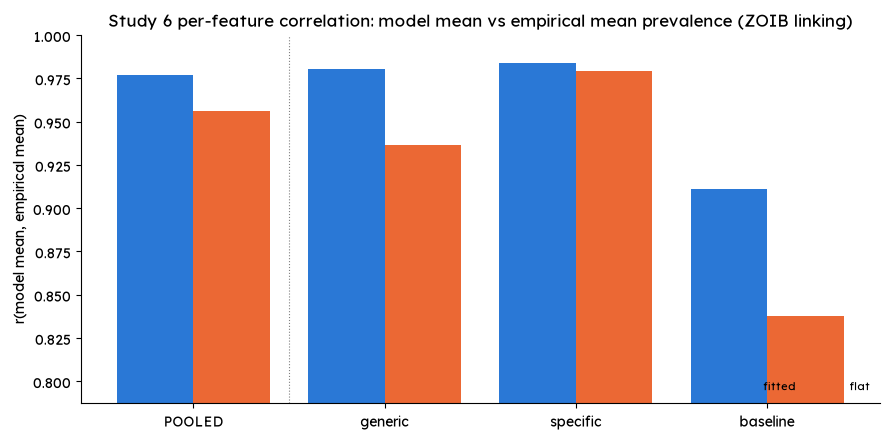

In [4]:
emp_all = np.concatenate([emp_cond[c] for c in CONDITIONS])

def pooled(n, key='pred_cond'):
    return np.concatenate([fitres[n][key][c] for c in CONDITIONS])

r_pool = {n: np.corrcoef(pooled(n), emp_all)[0, 1] for n in names}
r_cond = {n: {c: np.corrcoef(fitres[n]['pred_cond'][c], emp_cond[c])[0, 1] for c in CONDITIONS}
          for n in names}

hdr = f"{'':<15}" + "".join(f"{n:>14}" for n in names)
print("r(model E[rating], empirical mean)  per feature   [ratings-conditioned coherence]\n")
print(hdr); print("-" * len(hdr))
print(f"{'POOLED':<15}" + "".join(f"{r_pool[n]:>+14.3f}" for n in names))
print("-" * len(hdr))
for c in CONDITIONS:
    print(f"{c:<15}" + "".join(f"{r_cond[n][c]:>+14.3f}" for n in names))

fig, ax = plt.subplots(figsize=(9, 4.5))
groups = ['POOLED'] + CONDITIONS
xg = np.arange(len(groups)); w = 0.8 / len(names)
allv = []
for i, n in enumerate(names):
    vals = [r_pool[n]] + [r_cond[n][c] for c in CONDITIONS]
    allv += vals
    ax.bar(xg + (i - (len(names)-1)/2)*w, vals, w, label=n, color=MODEL_COLOR[n])
ax.set_xticks(xg); ax.set_xticklabels(groups)
ax.set_ylabel('r(model mean, empirical mean)'); ax.set_ylim(max(0.0, min(allv) - 0.05), 1.0)
ax.axvline(0.5, color='gray', lw=0.8, ls=':')
ax.set_title('Study 6 per-feature correlation: model mean vs empirical mean prevalence (ZOIB linking)')
ax.legend(ncol=2, fontsize=8, loc='lower right')
plt.tight_layout()
out_png = os.path.join(RESULTS, 'correlation-bars-comparison.png')
fig.savefig(out_png, dpi=150, bbox_inches='tight')
print('saved', out_png)
plt.show()

## Predicted vs empirical scatter

Same layout as the study 9 figure (rows = model, columns = group). Study 9 colors points by trait and outlines
the matched trait; in study 6, 15/16 test features are `hobbies_behaviors` and groups aren't trait-matched, so
points are colored by model instead.

saved results/study6-fit-zoib/predicted-vs-empirical-scatter-comparison.png


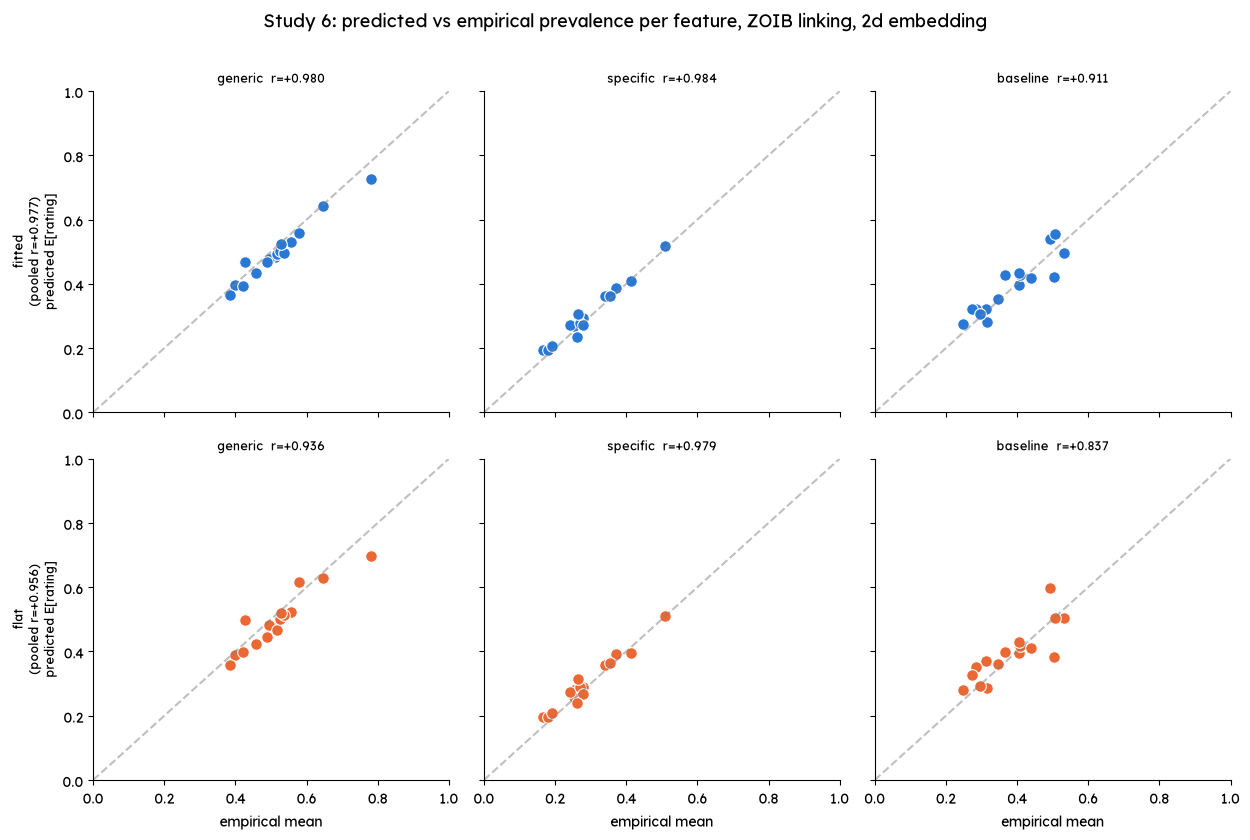

In [5]:
fig, axgrid = plt.subplots(len(MODELS), len(CONDITIONS),
                           figsize=(4.2*len(CONDITIONS), 4.2*len(MODELS)),
                           sharex=True, sharey=True)
for row, (name, m) in enumerate(MODELS.items()):
    pred_cond = fitres[name]['pred_cond']
    for col, c in enumerate(CONDITIONS):
        ax = axgrid[row, col]
        ax.scatter(emp_cond[c], pred_cond[c], s=70, color=MODEL_COLOR[name], edgecolor='white', linewidth=0.8)
        ax.plot([0, 1], [0, 1], '--', color='gray', alpha=0.5)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        r = np.corrcoef(pred_cond[c], emp_cond[c])[0, 1]
        ax.set_title(f"{c}  r={r:+.3f}", fontsize=9)
        if col == 0:
            r_pool_row = np.corrcoef(np.concatenate([pred_cond[cc] for cc in CONDITIONS]), emp_all)[0, 1]
            ax.set_ylabel(f"{name}\n(pooled r={r_pool_row:+.3f})\npredicted E[rating]", fontsize=9)
        if row == len(MODELS) - 1:
            ax.set_xlabel('empirical mean')
fig.suptitle('Study 6: predicted vs empirical prevalence per feature, ZOIB linking, 2d embedding',
             fontsize=13, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.985])
out_png = os.path.join(RESULTS, 'predicted-vs-empirical-scatter-comparison.png')
fig.savefig(out_png, dpi=150, bbox_inches='tight')
print('saved', out_png)
plt.show()